Exploratory Data Analysis (EDA)

In this phase, we conduct a comprehensive Exploratory Data Analysis (EDA) on our bus passenger demand dataset. This process helps us understand the underlying distribution of the target variable, find correlations, detect temporal patterns, identify missing or duplicate records, and establish a robust chronological train/validation/test split.

## Step 1: Import Libraries and Load Dataset

First, we import the necessary scientific computing, visualization, and machine learning libraries. We then load the bus demand dataset directly from our local path.

In [20]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42
np.random.seed(SEED)

DATA_PATH = '/content/bus_demand.csv'
df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully!')
print('Dataset shape:', df.shape)

Dataset loaded successfully!
Dataset shape: (90651, 22)


## Step 2: Understand the Dataset Structure

We print the top and bottom records, examine the available columns, and review the structural information of our DataFrame.

In [21]:
display(df.head())
display(df.tail())
print('Columns in dataset:')
print(df.columns.tolist())
df.info()

,trip_id,route_id,origin,destination,distance_km,route_type,departure_datetime,capacity,ticket_fare_inr,planned_event_flag,...,passengers,date,hour,weekday,month,season,is_weekend,is_peak,occupancy_rate,is_full
0,R11-20240101-05,R11,Patiala,Chandigarh,65,commuter,2024-01-01 05:00:00,40.0,125.53,0,...,12,2024-01-01,5,0,1,winter,0,0,0.300,0
1,R06-20240101-05,R06,Amritsar,Pathankot,110,intercity,2024-01-01 05:15:00,40.0,178.66,0,...,15,2024-01-01,5,0,1,winter,0,0,0.375,0
2,R02-20240101-05,R02,Amritsar,Delhi,450,intercity,2024-01-01 05:45:00,50.0,781.36,0,...,36,2024-01-01,5,0,1,winter,0,0,0.720,0
3,R01-20240101-06,R01,Amritsar,Chandigarh,230,intercity,2024-01-01 06:15:00,45.0,465.83,0,...,45,2024-01-01,6,0,1,winter,0,1,1.000,1
4,R06-20240101-06,R06,Amritsar,Pathankot,110,intercity,2024-01-01 06:15:00,40.0,194.49,0,...,21,2024-01-01,6,0,1,winter,0,1,0.525,0


,trip_id,route_id,origin,destination,distance_km,route_type,departure_datetime,capacity,ticket_fare_inr,planned_event_flag,...,passengers,date,hour,weekday,month,season,is_weekend,is_peak,occupancy_rate,is_full
90646,R11-20260630-20,R11,Patiala,Chandigarh,65,commuter,2026-06-30 20:45:00,40.0,124.51,0,...,40,2026-06-30,20,1,6,monsoon,0,1,1.000,1
90647,R09-20260630-20,R09,Delhi,Jaipur,280,intercity,2026-06-30 20:45:00,50.0,635.14,0,...,50,2026-06-30,20,1,6,monsoon,0,1,1.000,1
90648,R01-20260630-21,R01,Amritsar,Chandigarh,230,intercity,2026-06-30 21:15:00,45.0,453.79,0,...,27,2026-06-30,21,1,6,monsoon,0,0,0.600,0
90649,R10-20260630-22,R10,Ludhiana,Amritsar,140,intercity,2026-06-30 22:30:00,45.0,232.79,0,...,27,2026-06-30,22,1,6,monsoon,0,0,0.600,0
90650,R11-20260630-22,R11,Patiala,Chandigarh,65,commuter,2026-06-30 22:45:00,40.0,118.62,0,...,11,2026-06-30,22,1,6,monsoon,0,0,0.275,0


Columns in dataset:
['trip_id', 'route_id', 'origin', 'destination', 'distance_km', 'route_type', 'departure_datetime', 'capacity', 'ticket_fare_inr', 'planned_event_flag', 'public_holiday_flag', 'disruption_flag', 'passengers', 'date', 'hour', 'weekday', 'month', 'season', 'is_weekend', 'is_peak', 'occupancy_rate', 'is_full']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90651 entries, 0 to 90650
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   trip_id              90651 non-null  object 
 1   route_id             90651 non-null  object 
 2   origin               90651 non-null  object 
 3   destination          90651 non-null  object 
 4   distance_km          90651 non-null  int64  
 5   route_type           90651 non-null  object 
 6   departure_datetime   90651 non-null  object 
 7   capacity             90199 non-null  float64
 8   ticket_fare_inr      89745 non-null  float64
 9   planned

## Step 3: Standardize Date and Hour Columns

To ensure uniformity in our downstream analysis, we rename the 'date' and 'hour' columns to 'journey_date' and 'departure_hour', respectively. We then convert the dates to pandas datetime objects and determine the start and end of our observation period.

In [22]:
df.rename(columns={'date': 'journey_date', 'hour': 'departure_hour'}, inplace=True)
df['journey_date'] = pd.to_datetime(df['journey_date'], errors='coerce')
print('Date range:')
print('Start:', df['journey_date'].min())
print('End:', df['journey_date'].max())
display(df.head())

Date range:
Start: 2024-01-01 00:00:00
End: 2026-06-30 00:00:00


,trip_id,route_id,origin,destination,distance_km,route_type,departure_datetime,capacity,ticket_fare_inr,planned_event_flag,...,passengers,journey_date,departure_hour,weekday,month,season,is_weekend,is_peak,occupancy_rate,is_full
0,R11-20240101-05,R11,Patiala,Chandigarh,65,commuter,2024-01-01 05:00:00,40.0,125.53,0,...,12,2024-01-01,5,0,1,winter,0,0,0.300,0
1,R06-20240101-05,R06,Amritsar,Pathankot,110,intercity,2024-01-01 05:15:00,40.0,178.66,0,...,15,2024-01-01,5,0,1,winter,0,0,0.375,0
2,R02-20240101-05,R02,Amritsar,Delhi,450,intercity,2024-01-01 05:45:00,50.0,781.36,0,...,36,2024-01-01,5,0,1,winter,0,0,0.720,0
3,R01-20240101-06,R01,Amritsar,Chandigarh,230,intercity,2024-01-01 06:15:00,45.0,465.83,0,...,45,2024-01-01,6,0,1,winter,0,1,1.000,1
4,R06-20240101-06,R06,Amritsar,Pathankot,110,intercity,2024-01-01 06:15:00,40.0,194.49,0,...,21,2024-01-01,6,0,1,winter,0,1,0.525,0


## Step 4: Missing Value Analysis

We check for missing values across all features to determine if data imputation or removal of incomplete rows is needed. We also visualize the presence of missing elements using a heatmap.

,Missing Count,Missing Percentage
ticket_fare_inr,906,1.0
capacity,452,0.5
origin,0,0.0
destination,0,0.0
trip_id,0,0.0
route_id,0,0.0
route_type,0,0.0
distance_km,0,0.0
departure_datetime,0,0.0
planned_event_flag,0,0.0


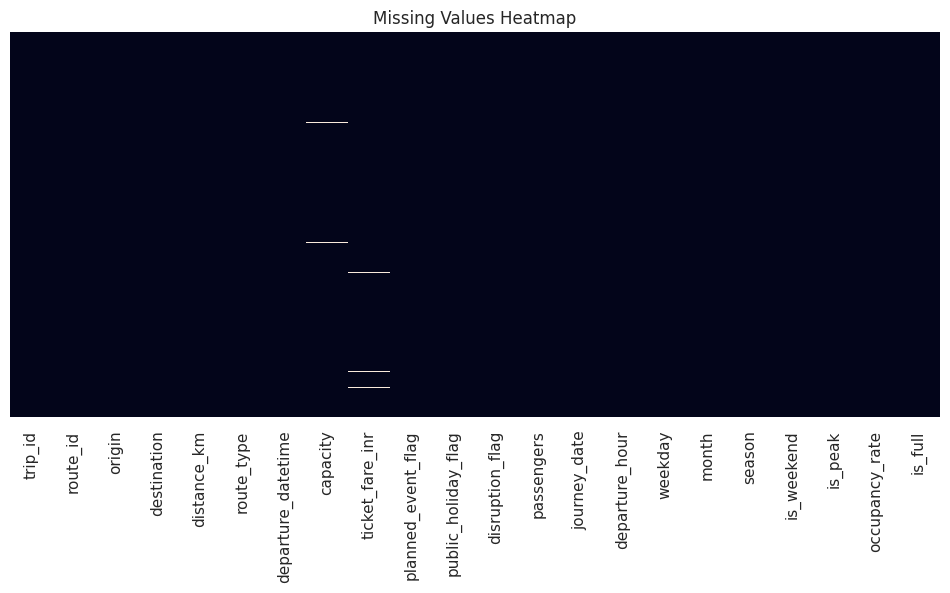

In [23]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})
display(missing.sort_values(by='Missing Percentage', ascending=False))

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing Values Heatmap')
plt.show()

## Step 5: Duplicate Records Analysis

We count and inspect duplicate entries within our dataset. This includes checking general duplicate rows and duplicate 'trip_id' entries if applicable.

In [24]:
print('Total duplicate rows:', df.duplicated().sum())
if 'trip_id' in df.columns:
    print('Duplicate trip IDs:', df['trip_id'].duplicated().sum())

duplicates = df[df.duplicated(keep=False)]
display(duplicates.head(10))

Total duplicate rows: 180
Duplicate trip IDs: 180


,trip_id,route_id,origin,destination,distance_km,route_type,departure_datetime,capacity,ticket_fare_inr,planned_event_flag,...,passengers,journey_date,departure_hour,weekday,month,season,is_weekend,is_peak,occupancy_rate,is_full
24,R06-20240101-08,R06,Amritsar,Pathankot,110,intercity,2024-01-01 08:30:00,40.0,192.11,0,...,21,2024-01-01,8,0,1,winter,0,1,0.525,0
25,R06-20240101-08,R06,Amritsar,Pathankot,110,intercity,2024-01-01 08:30:00,40.0,192.11,0,...,21,2024-01-01,8,0,1,winter,0,1,0.525,0
339,R02-20240104-13,R02,Amritsar,Delhi,450,intercity,2024-01-04 13:15:00,50.0,727.77,0,...,41,2024-01-04,13,3,1,winter,0,0,0.820,0
340,R02-20240104-13,R02,Amritsar,Delhi,450,intercity,2024-01-04 13:15:00,50.0,727.77,0,...,41,2024-01-04,13,3,1,winter,0,0,0.820,0
941,R05-20240110-15,R05,Jalandhar,Ludhiana,60,commuter,2024-01-10 15:45:00,40.0,109.54,0,...,23,2024-01-10,15,2,1,winter,0,0,0.575,0
942,R05-20240110-15,R05,Jalandhar,Ludhiana,60,commuter,2024-01-10 15:45:00,40.0,109.54,0,...,23,2024-01-10,15,2,1,winter,0,0,0.575,0
1327,R09-20240114-14,R09,Delhi,Jaipur,280,intercity,2024-01-14 14:15:00,50.0,587.50,0,...,41,2024-01-14,14,6,1,winter,1,0,0.820,0
1328,R09-20240114-14,R09,Delhi,Jaipur,280,intercity,2024-01-14 14:15:00,50.0,587.50,0,...,41,2024-01-14,14,6,1,winter,1,0,0.820,0
1598,R06-20240117-09,R06,Amritsar,Pathankot,110,intercity,2024-01-17 09:30:00,40.0,202.70,0,...,32,2024-01-17,9,2,1,winter,0,1,0.800,0
1601,R06-20240117-09,R06,Amritsar,Pathankot,110,intercity,2024-01-17 09:30:00,40.0,202.70,0,...,32,2024-01-17,9,2,1,winter,0,1,0.800,0


## Step 6: Statistical Profiling

We inspect numerical distributions and explore the unique value counts for categorical variables to gain foundational insight into our feature spaces.

In [25]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
print('Numerical columns:', numerical_columns)
display(df[numerical_columns].describe().T)

categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()
print('Categorical columns:', categorical_columns)
for col in categorical_columns:
    print(f'\n{col}:')
    print(df[col].value_counts().head(10))

Numerical columns: ['distance_km', 'capacity', 'ticket_fare_inr', 'planned_event_flag', 'public_holiday_flag', 'disruption_flag', 'passengers', 'departure_hour', 'weekday', 'month', 'is_weekend', 'is_peak', 'occupancy_rate', 'is_full']


,count,mean,std,min,25%,50%,75%,max
distance_km,90651.0,155.534192,115.063744,60.00,65.000,110.000,230.000,450.00
capacity,90199.0,43.668999,3.681407,35.00,40.000,45.000,45.000,50.00
ticket_fare_inr,89745.0,315.995382,233.591456,92.64,126.410,199.140,452.460,1040.27
planned_event_flag,90651.0,0.002449,0.049427,0.00,0.000,0.000,0.000,1.00
public_holiday_flag,90651.0,0.017540,0.131272,0.00,0.000,0.000,0.000,1.00
disruption_flag,90651.0,0.001809,0.042496,0.00,0.000,0.000,0.000,1.00
passengers,90651.0,31.445963,11.862590,0.00,22.000,32.000,40.000,138.00
departure_hour,90651.0,13.199248,4.899602,5.00,9.000,13.000,17.000,22.00
weekday,90651.0,2.994385,2.001280,0.00,1.000,3.000,5.000,6.00
month,90651.0,5.929742,3.401352,1.00,3.000,6.000,9.000,12.00


Categorical columns: ['trip_id', 'route_id', 'origin', 'destination', 'route_type', 'departure_datetime', 'season']

trip_id:
trip_id
R01-20251027-17    2
R04-20251019-21    2
R03-20241123-05    2
R10-20251209-08    2
R01-20250705-17    2
R05-20260412-14    2
R04-20250525-06    2
R05-20250710-16    2
R04-20250801-10    2
R11-20250410-15    2
Name: count, dtype: int64

route_id:
route_id
R05    12803
R03    10963
R11    10962
R04     9142
R09     7313
R10     7311
R01     7310
R02     7307
R06     7303
R07     5484
Name: count, dtype: int64

origin:
origin
Amritsar      33980
Ludhiana      16453
Jalandhar     12803
Patiala       10962
Chandigarh     9140
Delhi          7313
Name: count, dtype: int64

destination:
destination
Chandigarh     27414
Ludhiana       12803
Jalandhar      10963
Jaipur          7313
Amritsar        7311
Delhi           7307
Pathankot       7303
Shimla          5484
Manali          3656
Dharamshala     1097
Name: count, dtype: int64

route_type:
route_type
interc

## Step 7: Passenger Target Variable Distribution

Because 'passengers' is our target variable for forecasting, we analyze its distribution metrics and plot its frequency histogram.

Passenger statistics:
count    90651.000000
mean        31.445963
std         11.862590
min          0.000000
25%         22.000000
50%         32.000000
75%         40.000000
max        138.000000
Name: passengers, dtype: float64


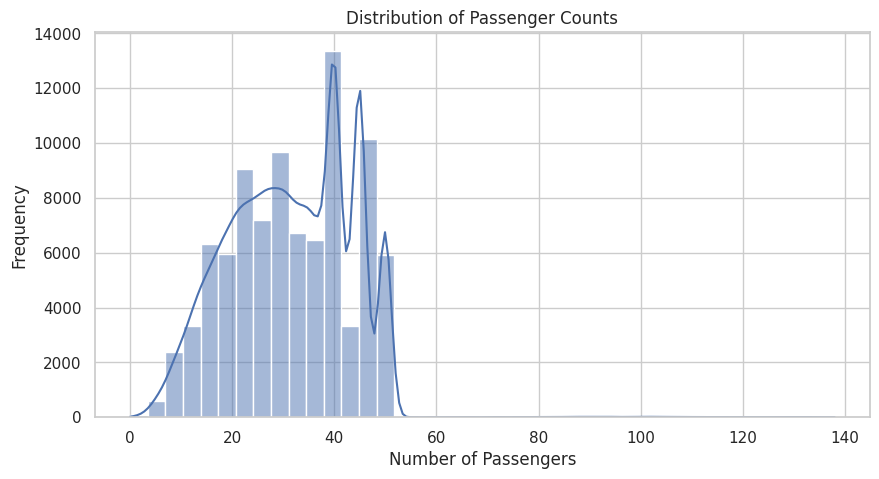

In [26]:
print('Passenger statistics:')
print(df['passengers'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['passengers'], bins=40, kde=True)
plt.title('Distribution of Passenger Counts')
plt.xlabel('Number of Passengers')
plt.ylabel('Frequency')
plt.show()

## Step 8: Outlier Detection

Using the Interquartile Range (IQR) method, we determine bounds for typical passenger numbers and quantify extreme demand events. Note that outliers are retained for now, as they represent vital real-world peak demands.

Q1: 22.0
Q3: 40.0
IQR: 18.0
Lower bound: -5.0
Upper bound: 67.0

Outlier count: 168
Outlier percentage: 0.19 %


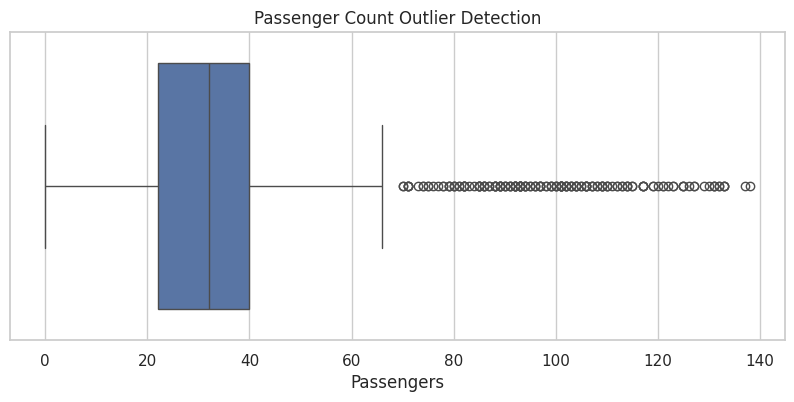

In [27]:
Q1 = df['passengers'].quantile(0.25)
Q3 = df['passengers'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['passengers'] < lower_bound) | (df['passengers'] > upper_bound)]

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Lower bound:', lower_bound)
print('Upper bound:', upper_bound)
print('\nOutlier count:', len(outliers))
print('Outlier percentage:', round(len(outliers) / len(df) * 100, 2), '%')

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['passengers'])
plt.title('Passenger Count Outlier Detection')
plt.xlabel('Passengers')
plt.show()

## Step 9: Passenger Demand by Route

We group the dataset by route ID to analyze which lines experience the highest average volume, and visualize the averages.

,mean,median,min,max,count
route_id,,,,,
R02,43.316956,48.0,10,138,7307
R09,39.855600,41.0,7,137,7313
R01,38.793023,43.0,5,133,7310
R03,33.590076,34.0,5,133,10963
R04,31.894006,32.0,3,133,9142
R10,29.072083,29.0,3,112,7311
R08,28.626915,28.0,2,106,3656
R05,27.512692,28.0,1,121,12803
R07,25.953501,26.0,1,106,5484


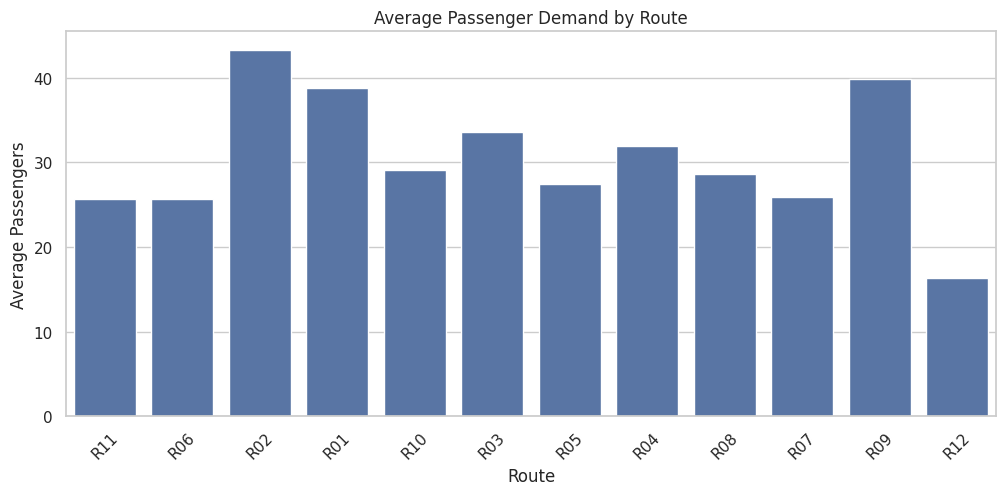

In [28]:
route_demand = df.groupby('route_id')['passengers'].agg(['mean', 'median', 'min', 'max', 'count']).sort_values('mean', ascending=False)
display(route_demand)

plt.figure(figsize=(12, 5))
sns.barplot(data=df, x='route_id', y='passengers', estimator='mean', errorbar=None)
plt.title('Average Passenger Demand by Route')
plt.xlabel('Route')
plt.ylabel('Average Passengers')
plt.xticks(rotation=45)
plt.show()

## Step 10: Passenger Demand by Departure Hour

We study hourly demand trends to track daily rush hour periods.

,departure_hour,passengers
0,5,26.720245
1,6,35.877296
2,7,35.811088
3,8,35.541349
4,9,35.720751
5,10,27.614423
6,11,26.307219
7,12,26.518967
8,13,26.589195
9,14,26.423034


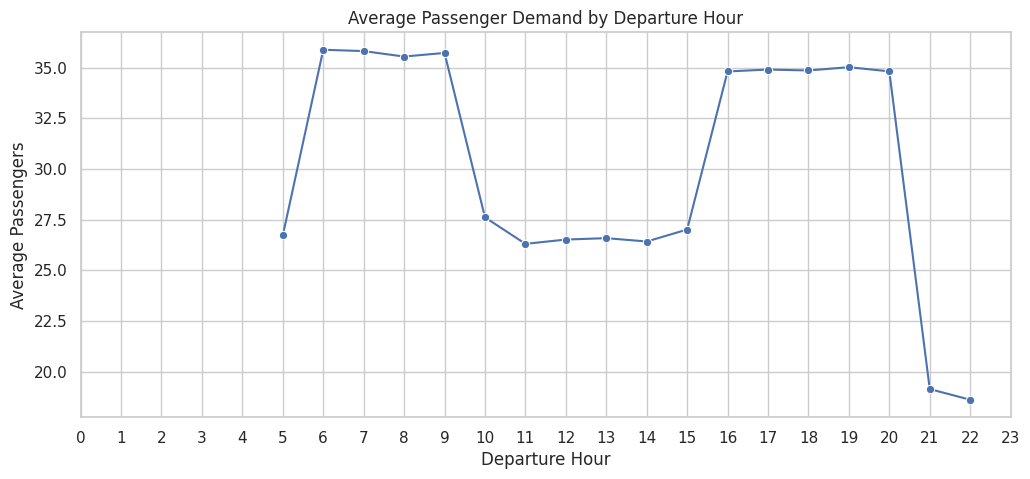

In [29]:
hour_demand = df.groupby('departure_hour')['passengers'].mean().reset_index()
display(hour_demand)

plt.figure(figsize=(12, 5))
sns.lineplot(data=hour_demand, x='departure_hour', y='passengers', marker='o')
plt.title('Average Passenger Demand by Departure Hour')
plt.xlabel('Departure Hour')
plt.ylabel('Average Passengers')
plt.xticks(range(0, 24))
plt.show()

## Step 11: Passenger Demand by Season

We observe how seasons affect ridership behaviors using summary statistics and boxplots.

,mean,median,count
season,,,
autumn,34.199359,36.0,12164
monsoon,28.904308,28.0,27275
summer,32.992986,34.0,27374
winter,31.172582,31.0,23838


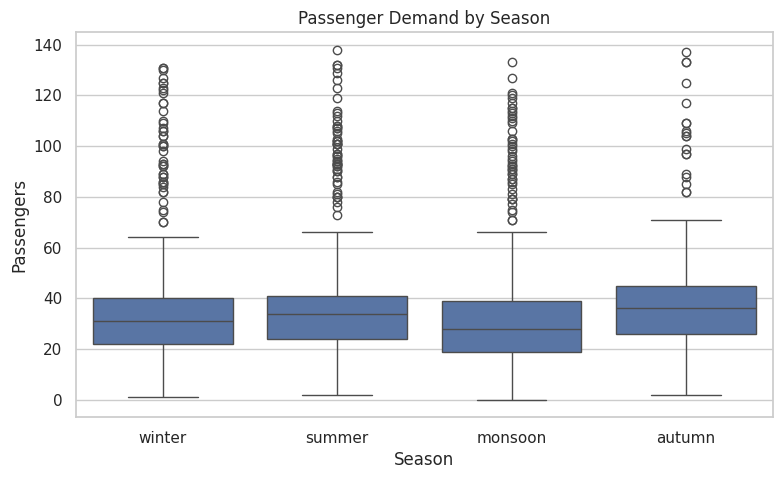

In [30]:
season_demand = df.groupby('season')['passengers'].agg(['mean', 'median', 'count'])
display(season_demand)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='season', y='passengers')
plt.title('Passenger Demand by Season')
plt.xlabel('Season')
plt.ylabel('Passengers')
plt.show()

## Step 12: Weekend vs. Weekday Demand

We investigate differences in ridership habits between weekdays and weekend periods.

,is_weekend,passengers,Day Type
0,0,31.480058,Weekday
1,1,31.360438,Weekend


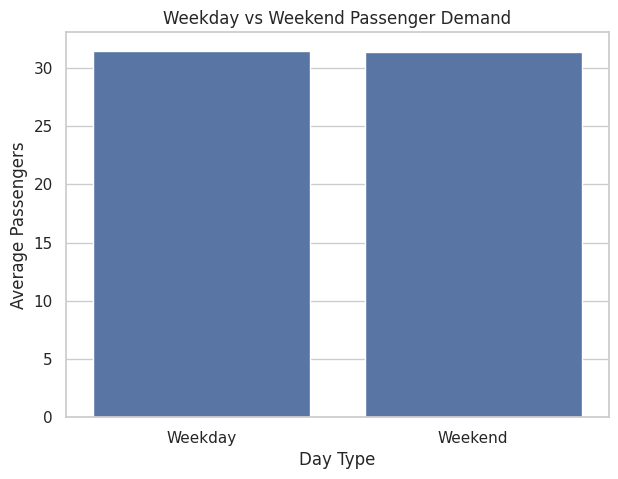

In [31]:
weekend_demand = df.groupby('is_weekend')['passengers'].mean().reset_index()
weekend_demand['Day Type'] = weekend_demand['is_weekend'].map({0: 'Weekday', 1: 'Weekend'})
display(weekend_demand)

plt.figure(figsize=(7, 5))
sns.barplot(data=weekend_demand, x='Day Type', y='passengers')
plt.title('Weekday vs Weekend Passenger Demand')
plt.ylabel('Average Passengers')
plt.show()

## Step 13: Peak vs. Non-Peak Demand

We compare average passenger demand during predefined peak and non-peak hours.

,is_peak,passengers,Period
0,0,25.618512,Non-Peak
1,1,35.272817,Peak


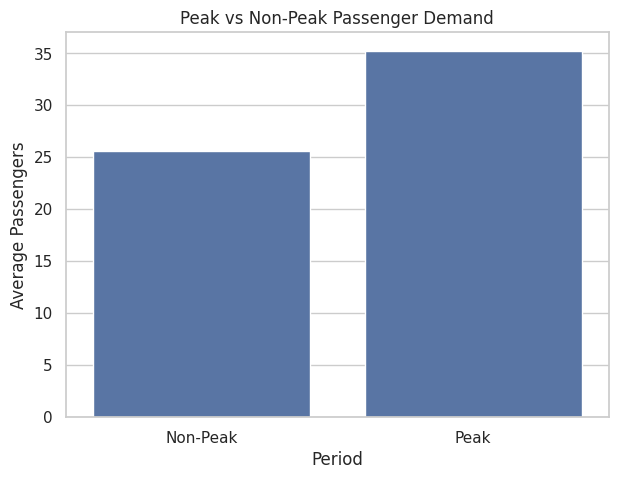

In [32]:
peak_demand = df.groupby('is_peak')['passengers'].mean().reset_index()
peak_demand['Period'] = peak_demand['is_peak'].map({0: 'Non-Peak', 1: 'Peak'})
display(peak_demand)

plt.figure(figsize=(7, 5))
sns.barplot(data=peak_demand, x='Period', y='passengers')
plt.title('Peak vs Non-Peak Passenger Demand')
plt.ylabel('Average Passengers')
plt.show()

## Step 14: Feature Correlation Heatmap

We measure correlations across all numeric variables. Note that target leak variables like occupancy_rate and is_full cannot be used as features during modeling.

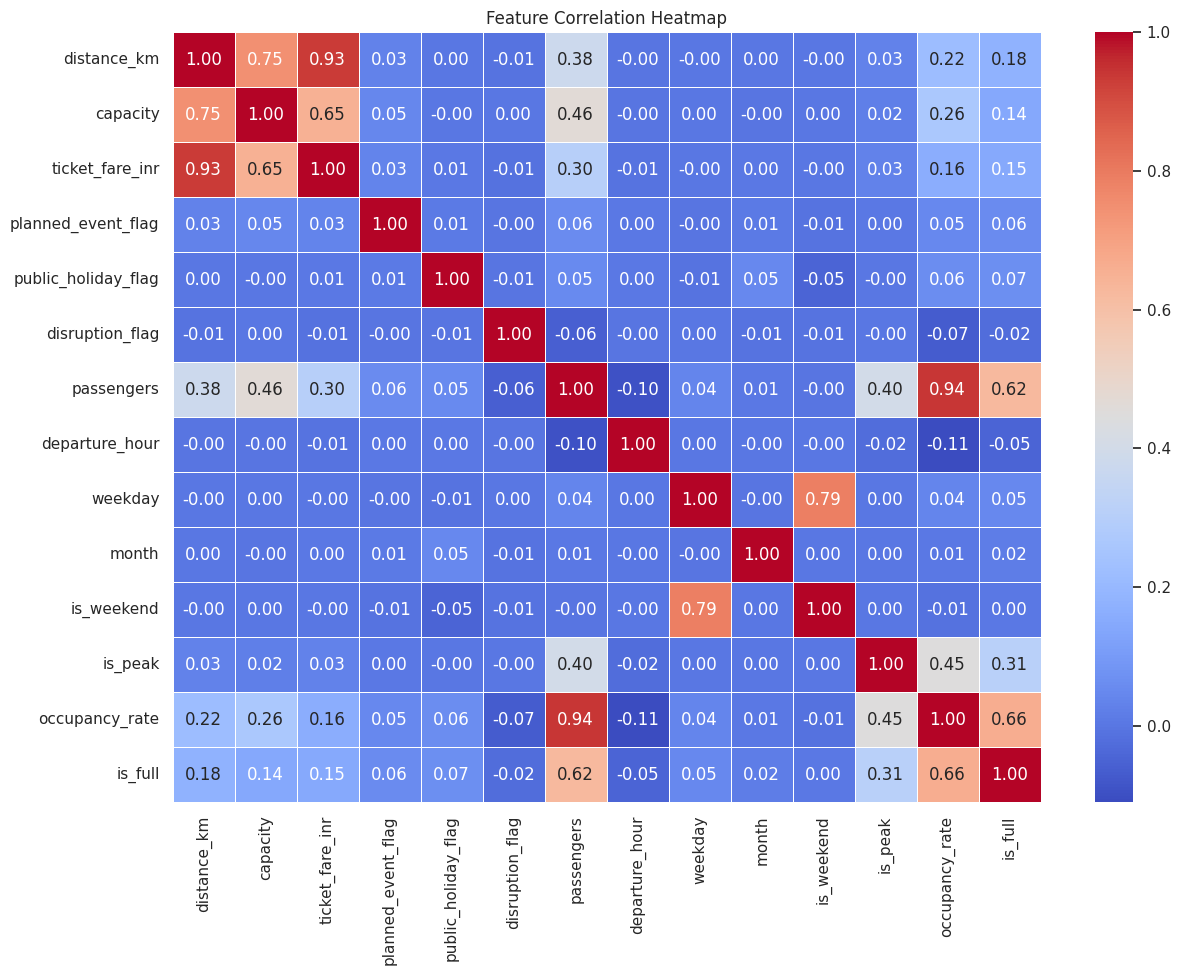

In [33]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

## Step 15: Passenger Demand Over Time

We aggregate demand by date to plot overall chronological trends in ridership.

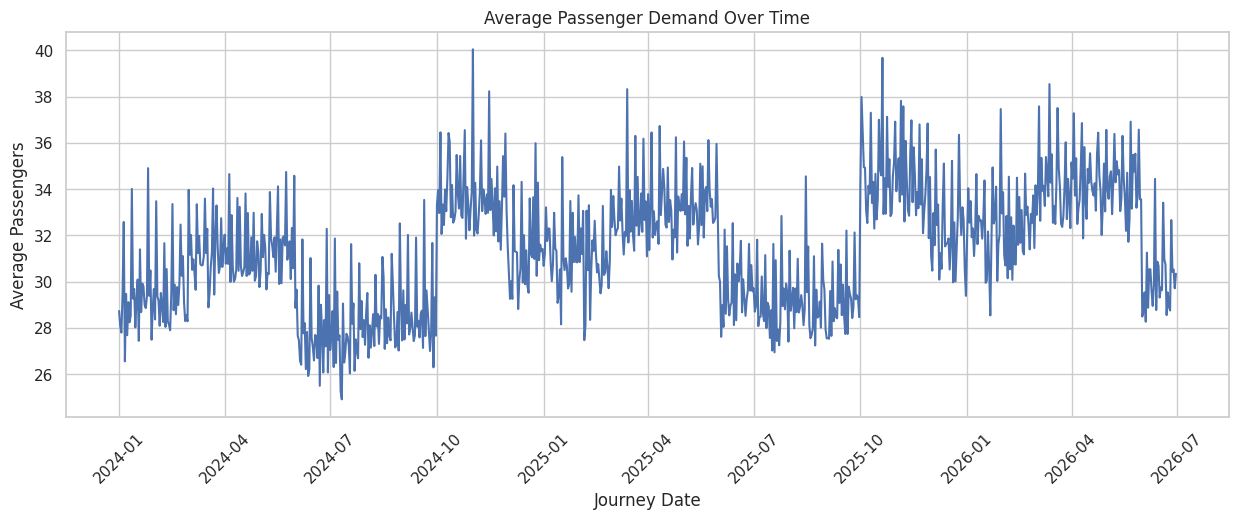

In [34]:
daily_demand = df.groupby('journey_date')['passengers'].mean().reset_index().sort_values('journey_date')
plt.figure(figsize=(15, 5))
sns.lineplot(data=daily_demand, x='journey_date', y='passengers')
plt.title('Average Passenger Demand Over Time')
plt.xlabel('Journey Date')
plt.ylabel('Average Passengers')
plt.xticks(rotation=45)
plt.show()

## Step 16: Chronological Train, Validation, and Test Split

We establish standard temporal splits: Training from Jan 2024 to June 2025, Validation from July 2025 to Dec 2025, and a reserved Test set from Jan 2026 to June 2026.

In [35]:
df = df.dropna(subset=['journey_date', 'route_id', 'passengers']).copy()

train = df[(df['journey_date'] >= '2024-01-01') & (df['journey_date'] <= '2025-06-30')].copy()
validation = df[(df['journey_date'] >= '2025-07-01') & (df['journey_date'] <= '2025-12-31')].copy()
test = df[(df['journey_date'] >= '2026-01-01') & (df['journey_date'] <= '2026-06-30')].copy()

print('Training records:', len(train))
print('Validation records:', len(validation))
print('Test records reserved:', len(test))

Training records: 53714
Validation records: 18625
Test records reserved: 18312


## Step 17: Save Split Datasets

Finally, we export the structured splits into files to ensure consistency across the upcoming pipeline modeling phases.

In [36]:
os.makedirs('/content/processed', exist_ok=True)
train.to_csv('/content/processed/train.csv', index=False)
validation.to_csv('/content/processed/validation.csv', index=False)
test.to_csv('/content/processed/test_reserved.csv', index=False)
print('Datasets saved successfully!')

Datasets saved successfully!


```markdown
## Step 18: Distribution and Boxplots for All Numeric Columns

To ensure a thorough understanding of the numeric feature space, we loop through all numerical columns in the dataset to plot their individual distribution histograms (with kernel density estimates) and boxplots.
```

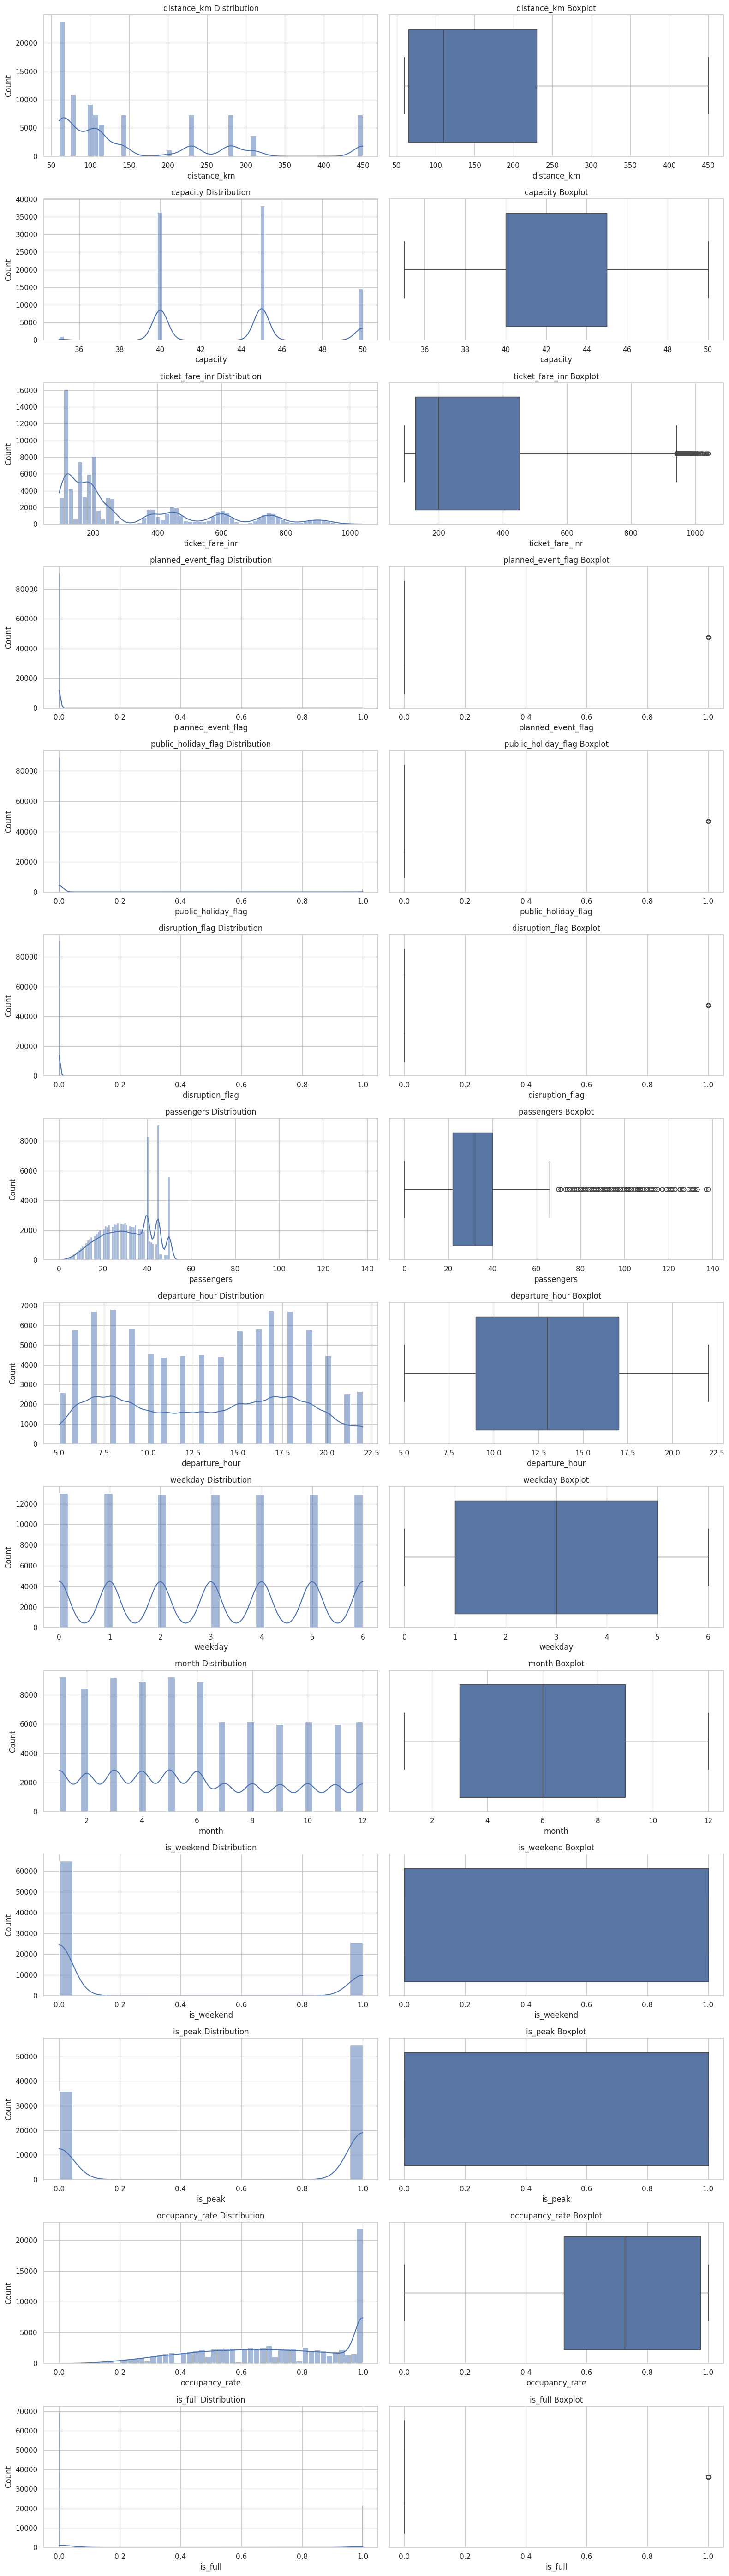

In [37]:
import math

# Identify numerical columns to plot (excluding identifiers or highly repetitive values if necessary, but plotting all here)
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Setup the grid for plotting
num_cols_to_plot = len(numeric_cols)
cols_per_row = 2
rows = math.ceil(num_cols_to_plot * 2 / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row, figsize=(16, 4 * rows))
axes = axes.flatten()

plot_idx = 0
for col in numeric_cols:
    # Histplot
    sns.histplot(df[col].dropna(), kde=True, ax=axes[plot_idx])
    axes[plot_idx].set_title(f'{col} Distribution')
    plot_idx += 1

    # Boxplot
    sns.boxplot(x=df[col].dropna(), ax=axes[plot_idx])
    axes[plot_idx].set_title(f'{col} Boxplot')
    plot_idx += 1

# Turn off empty axes if any
for i in range(plot_idx, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()